In [24]:
import numpy as np
import matplotlib.pyplot as plt

In [25]:
f = lambda x: 1 / (0.0001 + x**2)
a, b = -0.3, 0.3

Die folgende Funktion stammt aus dem Skript _(Code 5.6.2)_.

Sie führt rekursiv die adaptive Quadratur aus, indem fortlaufend auf einem Gitter die Trapez- und Simpson-Regel verwendet und miteinander verglichen werden. Überall dort wo die adaptive Quadratur einen *substantiellen Anteil des Gesamtfehlers* ausmacht, fügen wir neue Punkte ins Gitter ein, dann führen wir das Verfahren rekursiv wieder durch. 

In [26]:
def adaptquad(f, M, rtol=1e-14, abstol=1e-14, maxit=100000):
    h = np.diff(M)
    mp = 0.5 * (M[:-1] + M[1:])
    fx = f(M)
    fm = f(mp)

    trp_loc = h*(fx[:-1] + 2*fm + fx[1:]) / 4
    simp_loc= h*(fx[:-1] + 4*fm + fx[1:]) / 6

    I = simp_loc.sum()
    if (maxit <= 0):
        return I, M
    est_loc = abs(simp_loc - trp_loc)
    err_tot = est_loc.sum()

    if err_tot > rtol*abs(I) and err_tot > abstol:
        refcells = np.nonzero(est_loc > 0.9 * err_tot / len(est_loc))[0]

        new_bps = np.append(M, mp[refcells])
        new_grid = np.sort(new_bps)
        I, M = adaptquad(f, new_grid, rtol, abstol, maxit-1)

    return I, M

Die folgende Methode löst das Problem mit demselben grundsätzlichen Ansatz, aber iterativ, was unter umständen Speicherprobleme lösen kann und die Funktion minimal beschleunigt: 

In [27]:
def adapt_grid(f, grid, rtol=1e-14, abstol=1e-14, maxit=100000):
    h = np.diff(grid)
    mid = 0.5 * (grid[:-1] + grid[1:])
    I = f(grid[0])

    for i in range(maxit):
        fg = f(grid)
        fm = f(mid)

        T = h * (fg[:-1] + 2*fm + fg[1:]) / 4
        S = h * (fg[:-1] + 4*fm + fg[1:]) / 6
        I = np.sum(S)
        local_error = np.abs(S - T)
        error = np.sum(local_error)

        if error <= rtol * abs(I) or error <= abstol:
            return I, grid

        error_cells = np.nonzero(local_error > 0.9 * error / len(local_error))[0]
        
        grid = np.sort(np.append(grid, mid[error_cells]))
        h = np.diff(grid)
        mid = 0.5 * (grid[:-1] + grid[1:])
        
    return I, grid


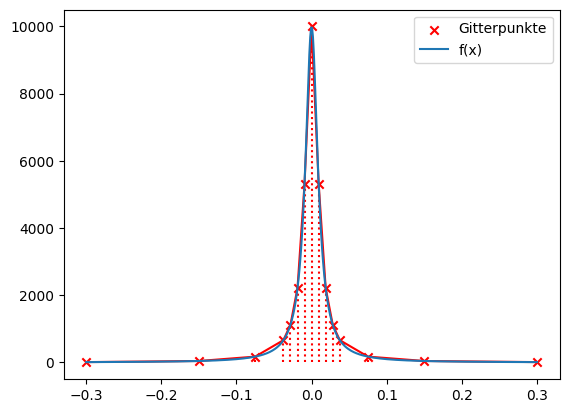

In [32]:
maxit = 6

approx, grid = adapt_grid(f, np.array((a, b)), maxit=maxit)
x = np.linspace(a, b, 500)


plt.vlines(grid, np.zeros(len(grid)), f(grid), color="red", linestyle=":")
plt.scatter(grid, f(grid), marker="x", label="Gitterpunkte", color="red")
plt.plot(grid, f(grid), color="red")

plt.plot(x, f(x), label=r"f(x)")

plt.legend()

## Zeitmessung 
Hier sehen wir noch das timing, wenn wir die adaptive Quadratur mit beiden Methoden bis zur Konvergenz laufen lassen: 

In [31]:
import time

start = time.time()
print(f"Resultat: {adaptquad(f, np.array((a, b)))[0]}")
end = time.time()
print(f"Rekursive Zeitmessung:\t{end - start}\n")

start = time.time()
print(f"Resultat: {adapt_grid(f, np.array((a, b)))[0]}")
end = time.time()
print(f"Iterative Zeitmessung:\t{end - start}")

Resultat: 307.49506618332987
Rekursive Zeitmessung:	5.255467891693115

Resultat: 307.49506618332987
Iterative Zeitmessung:	5.0661704540252686
